In [1]:
import xarray as xr

seapoint_to_sample = 1903794

whacs_station = xr.open_zarr("inputs/WHACS/NorthCarolina.zarr").sel(seapoint=1903794)
whacs_station

<xarray.Dataset> Size: 129MB
Dimensions:                      (time: 394464)
Coordinates:
  * time                         (time) datetime64[ns] 3MB 1979-01-01 ... 202...
    seapoint                     int32 4B 1903794
Data variables: (12/41)
    cge                          (time) float64 3MB dask.array<chunksize=(394464,), meta=np.ndarray>
    dir                          (time) float64 3MB dask.array<chunksize=(394464,), meta=np.ndarray>
    dp                           (time) float64 3MB dask.array<chunksize=(394464,), meta=np.ndarray>
    fp                           (time) float64 3MB dask.array<chunksize=(394464,), meta=np.ndarray>
    hs                           (time) float64 3MB dask.array<chunksize=(394464,), meta=np.ndarray>
    latitude                     (time) float32 2MB dask.array<chunksize=(394464,), meta=np.ndarray>
    ...                           ...
    ptp3                         (time) float64 3MB dask.array<chunksize=(394464,), meta=np.ndarray>
    spr                          (time) float64 3MB dask.array<chunksize=(394464,), meta=np.ndarray>
    t01                          (time) float64 3MB dask.array<chunksize=(394464,), meta=np.ndarray>
    t02                          (time) float64 3MB dask.array<chunksize=(394464,), meta=np.ndarray>
    uwnd                         (time) float64 3MB dask.array<chunksize=(394464,), meta=np.ndarray>
    vwnd                         (time) float64 3MB dask.array<chunksize=(394464,), meta=np.ndarray>
Attributes: (12/59)
    Conventions:                     CF-1.11 ACDD-1.3
    title:                           Wave Hindcast for the Australian Climate...
    summary:                         Wave Hindcast for the Australian Climate...
    keywords:                        WHACS, ACS, waves, ocean, coast, WWIII, ...
    id:                              BoM-CSIRO-WHACS-001
    naming_authority:                au.csiro
    ...                              ...
    geospatial_lon_max:              179.9375
    geospatial_vertical_positive:    up
    time_coverage_start:             1979-01-01T00:00:00
    time_coverage_end:               1979-01-31T23:00:00
    time_coverage_duration:          P30DT23H0M0S
    time_coverage_resolution:        P0DT1H0M0S

In [2]:
import pandas as pd

whacs_lon = float(whacs_station.longitude.values[-1])
whacs_lat = float(whacs_station.latitude.values[-1])

whacs_df = pd.DataFrame(
    {
        "Hs": whacs_station.hs.values,
        "Dp": whacs_station.dp.values,
        "Tp": 1 / whacs_station.fp.values,
        "DirM": whacs_station.dir.values,
        "Hsea": whacs_station.phs0.values,
        "Hswell1": whacs_station.phs1.values,
        "Hswell2": whacs_station.phs2.values,
        "Hswell3": whacs_station.phs3.values,
        "Dirsea": whacs_station.pdir0.values,
        "Dirswell1": whacs_station.pdir1.values,
        "Dirswell2": whacs_station.pdir2.values,
        "Dirswell3": whacs_station.pdir3.values,
    },
    index=pd.to_datetime(whacs_station.time.values),
)
whacs_df

,Hs,Dp,Tp,DirM,Hsea,Hswell1,Hswell2,Hswell3,Dirsea,Dirswell1,Dirswell2,Dirswell3
1979-01-01 00:00:00,0.730,140.0,3.831418,134.4,0.654,0.228,0.146,0.128,145.2,69.0,136.3,93.0
1979-01-01 01:00:00,0.750,142.0,3.968254,136.2,0.670,0.246,0.146,0.134,148.1,68.1,135.9,93.1
1979-01-01 02:00:00,0.766,144.0,4.032258,137.3,0.688,0.240,0.142,0.138,148.7,68.8,136.0,101.0
1979-01-01 03:00:00,0.784,145.0,4.081633,138.6,0.704,0.246,0.146,0.142,150.3,68.5,101.2,135.3
1979-01-01 04:00:00,0.822,146.0,4.132231,141.4,0.742,0.246,0.156,0.142,152.7,68.3,101.0,135.4
...,...,...,...,...,...,...,...,...,...,...,...,...
2023-12-31 19:00:00,1.166,224.0,6.369427,232.4,1.128,0.292,NaN,NaN,235.7,105.1,NaN,NaN
2023-12-31 20:00:00,1.288,233.0,4.608295,232.5,1.254,0.282,0.082,NaN,235.1,105.8,95.2,NaN
2023-12-31 21:00:00,1.408,233.0,4.950495,231.9,1.376,0.284,0.084,NaN,234.1,105.5,96.1,NaN
2023-12-31 22:00:00,1.484,230.0,5.319149,231.9,1.454,0.284,0.088,NaN,233.9,105.2,96.7,NaN


In [3]:
whacs_lon, whacs_lat

(-76.4375, 34.1875)

In [4]:
from bluemath_tk.waves.calibration import process_imos_satellite_data

imos_ds = xr.open_dataset("inputs/IMOS/processed/satellite_dataset_carolinas.nc")
imos_df = imos_ds[
    [
        "SWH_KU_CAL",
        "SWH_KA_CAL",
        "SWH_KU_quality_control",
        "SWH_KA_quality_control",
        "BOT_DEPTH",
        "LATITUDE",
        "LONGITUDE",
    ]
].to_dataframe()

distance_threshold = 0.15
imos_df_processed = process_imos_satellite_data(
    imos_df,
    ini_lat=whacs_lat - distance_threshold,
    end_lat=whacs_lat + distance_threshold,
    ini_lon=whacs_lon + 360 - distance_threshold,
    end_lon=whacs_lon + 360 + distance_threshold,
    depth_threshold=-30,
)
imos_df_processed

,SWH_KU_CAL,SWH_KA_CAL,SWH_KU_quality_control,SWH_KA_quality_control,BOT_DEPTH,LATITUDE,LONGITUDE,Hs_CAL
TIME,,,,,,,,
1985-04-29 12:46:47.210935280,2.597,NaN,1.0,NaN,-93.0,34.058060,283.710327,2.597
1985-04-29 12:46:48.187504112,2.366,NaN,1.0,NaN,-42.0,34.111996,283.680145,2.366
1985-04-29 12:46:49.171878174,2.405,NaN,1.0,NaN,-40.0,34.165924,283.649902,2.405
1985-04-29 12:46:50.148436948,2.588,NaN,1.0,NaN,-32.0,34.219849,283.619629,2.588
1985-04-29 12:46:51.132811010,2.626,NaN,1.0,NaN,-32.0,34.273766,283.589325,2.626
...,...,...,...,...,...,...,...,...
2024-11-20 02:42:47.999995136,1.068,NaN,1.0,NaN,-43.0,34.083824,283.622894,1.068
2024-11-20 02:42:48.999999744,1.062,NaN,1.0,NaN,-40.0,34.142464,283.605743,1.062
2024-12-01 10:37:10.999995648,NaN,0.637,NaN,1.0,-40.0,34.044216,283.418976,0.637


In [5]:
from bluemath_tk.waves.calibration import CalVal

calval = CalVal()
calval

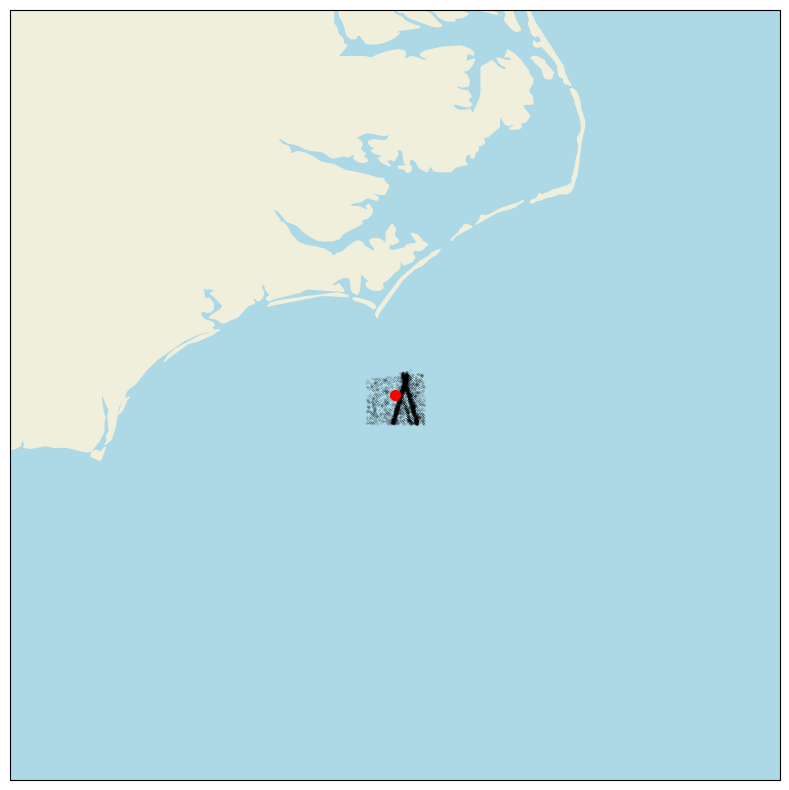

In [6]:
calval.fit(
    data=whacs_df,
    data_longitude=whacs_lon,
    data_latitude=whacs_lat,
    data_to_calibrate=imos_df_processed,
    max_time_diff=1,
)

In [7]:
calval.calibration_params

{'sea_correction': {0: 0.6139327164494333,
  1: 1.0263141453200653,
  2: 1.0054395338262856,
  3: 0.9395803946813883,
  4: 0.9074539803235606,
  5: 0.935404811427079,
  6: 0.9588521281053302,
  7: 0.9235587287043402,
  8: 0.9768752304169831,
  9: 1.0344585924200989,
  10: 0.9888887739012737,
  11: 1.1343741168874928,
  12: 1.138592210256955,
  13: 1.0724227471335814,
  14: 1.184161006142798,
  15: 1.1589554414412735},
 'swell_correction': {0: 0.8394901447453541,
  1: 1.0,
  2: 1.1093602451238336,
  3: 1.035366390543469,
  4: 0.9943189369401576,
  5: 1.0631639909986235,
  6: 0.896697738985115,
  7: 1.005814167428533,
  8: 1.0027634719782752,
  9: 0.9998465441582145,
  10: 0.974526246575119,
  11: 1.1456913044823442,
  12: 1.0,
  13: 1.0,
  14: 1.0,
  15: 1.0,
  16: 1.0}}

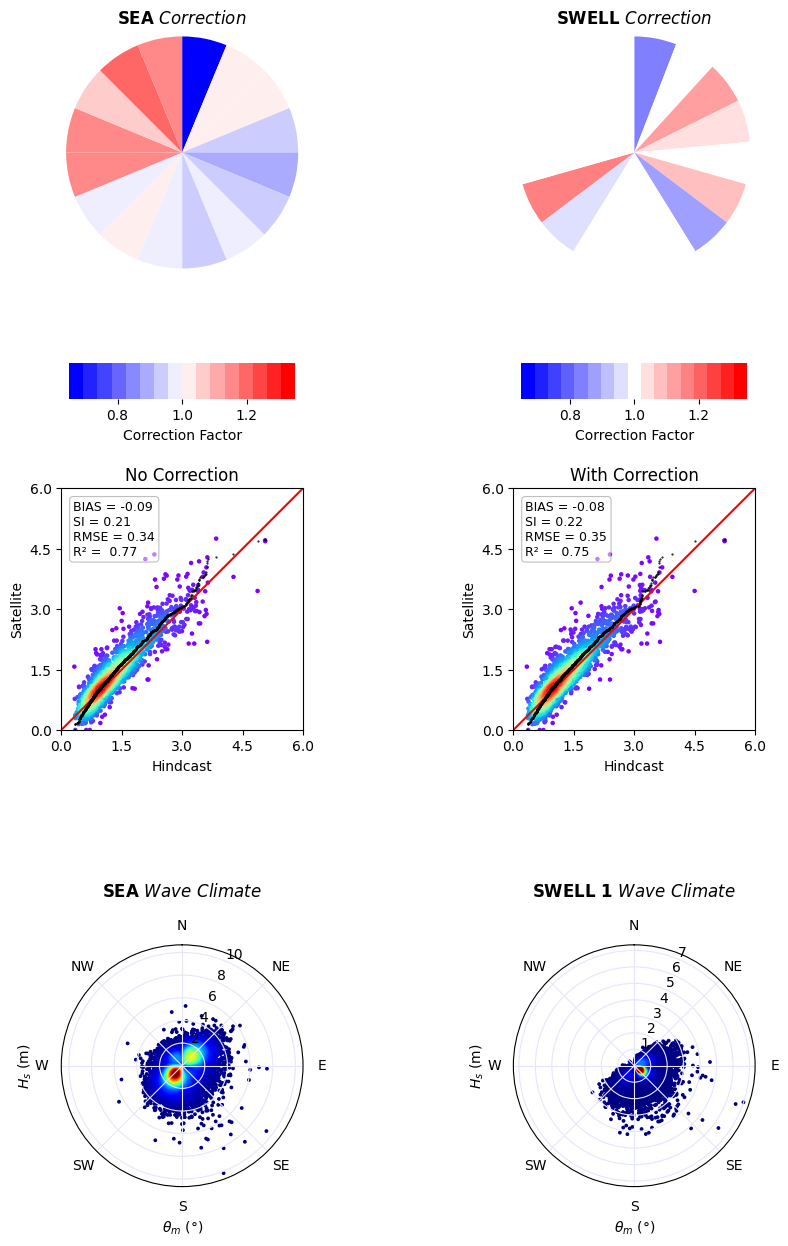

In [8]:
calval.plot_calibration_results();

In [9]:
corrected_whacs = calval.correct(data=whacs_df)
corrected_whacs

,Hs,Hs_CORR
1979-01-01 00:00:00,0.730,0.694482
1979-01-01 01:00:00,0.750,0.715878
1979-01-01 02:00:00,0.766,0.729369
1979-01-01 03:00:00,0.784,0.746879
1979-01-01 04:00:00,0.822,0.781878
...,...,...
2023-12-31 19:00:00,1.166,1.152633
2023-12-31 20:00:00,1.288,1.273984
2023-12-31 21:00:00,1.408,1.392211
2023-12-31 22:00:00,1.484,1.467922


In [14]:
buoy_df = (
    pd.read_csv(
        "inputs/JennBuoys/processed/buoy_41007_bulk_parameters.csv", index_col=0
    )
    .rename(columns={"Hs_Buoy": "Hs_VAL"})[["Hs_VAL"]]
    .dropna()
)
buoy_df.index = pd.to_datetime(buoy_df.index)
buoy_df

,Hs_VAL
datetime,
1986-01-18 18:00:00,1.10
1986-01-18 19:00:00,1.20
1986-01-18 20:00:00,1.15
1986-01-18 21:00:00,1.25
1986-01-18 22:00:00,1.40
...,...
1986-04-01 12:00:00,0.90
1986-04-01 13:00:00,0.80
1986-04-01 14:00:00,0.85


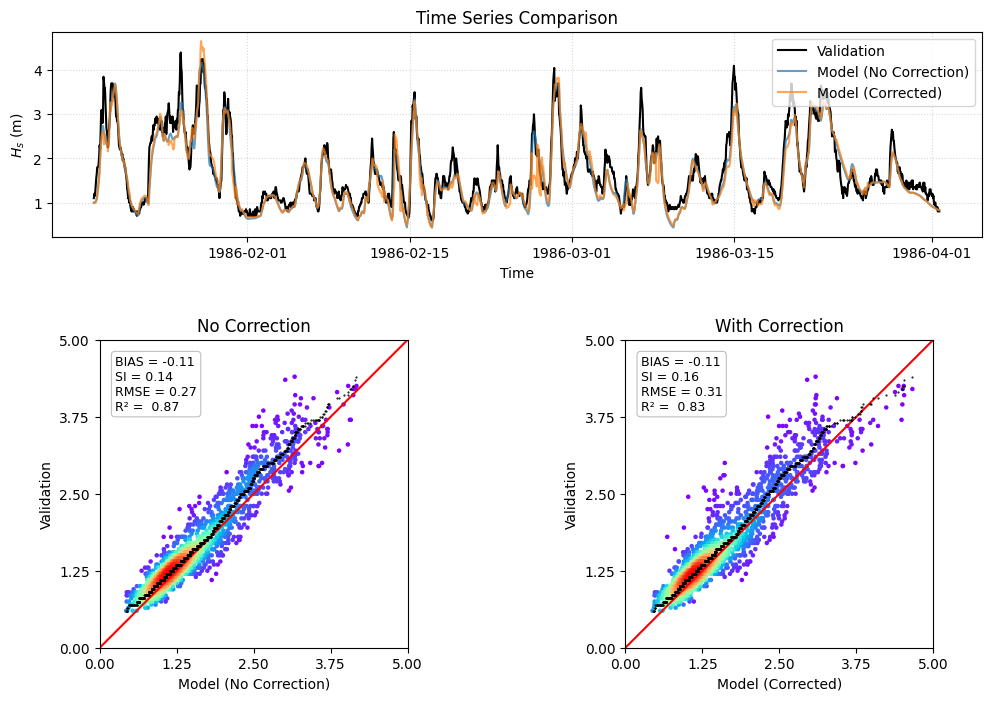

In [15]:
calval.validate_calibration(data_to_validate=buoy_df);